# Time Series Regression and Exploratory Data Analysis

**Reference:** Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press.

**R environment**

In [11]:
# Run in a Google Colab notebook with the R runtime.
packages = c("astsa", "dynlm", "zoo")
missing = packages[!sapply(packages, requireNamespace, quietly=TRUE)]
if (length(missing) > 0) install.packages(missing, repos="https://cloud.r-project.org")
library(astsa)
library(dynlm)
library(zoo)
options(digits=5)
par(mfrow=c(1,1))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘forecast’, ‘doBy’, ‘pbkrtest’, ‘car’


Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




## 1. Ordinary least squares for a time series

**Response** $x_t$: observation being modeled at time $t$. **Explanatory variables** $z_{t1},\ldots,z_{tq}$: quantities used to explain changes in $x_t$. **Exogenous** means specified outside the regression response; it does **not** by itself establish causal independence. **White-noise error** $w_t$: zero-mean errors with constant variance and zero autocorrelation at nonzero lags.

$$
x_t=\beta_0+\sum_{j=1}^{q}\beta_jz_{tj}+w_t,\qquad E(w_t)=0,\qquad \operatorname{Var}(w_t)=\sigma_w^2.
$$

- $\beta_0$ is the fitted response when all predictors equal zero; its real-world meaning depends on how predictors are scaled.
- $\beta_j$ is the conditional change in the response per one-unit increase in $z_{tj}$, holding the remaining predictors fixed.
- The distinction between **fitted value** $\hat{x}_t$ and **residual** $\hat{w}_t=x_t-\hat{x}_t$ matters: observed residuals diagnose assumptions about the unobserved error $w_t$.

**Ordinary least squares (OLS)** selects coefficients that minimize squared residuals:

$$
S(\boldsymbol{\beta})=\sum_{t=1}^{n}\left(x_t-\beta_0-\sum_{j=1}^{q}\beta_jz_{tj}\right)^2,
\qquad
\hat{\boldsymbol\beta}=\arg\min_{\boldsymbol\beta}S(\boldsymbol\beta).
$$

Time-series regression requires particular care: trends, seasonality, and serially correlated errors can produce apparently strong regression results even when standard OLS test assumptions are not met.

## 2. Linear trend: monthly Norwegian salmon export price

For the simple regression $x_t=\beta_0+\beta_1z_t+w_t$, use calendar time in **years** as $z_t$.

$$
\hat\beta_1=\frac{\sum_{t=1}^n(z_t-\bar z)(x_t-\bar x)}{\sum_{t=1}^n(z_t-\bar z)^2},
\qquad \hat\beta_0=\bar x-\hat\beta_1\bar z.
$$

The estimated slope is **USD per kilogram per year**, rather than per month, because $\texttt{time(salmon)}$ increases by 1 over 12 months.


Call:
lm(formula = salmon ~ time(salmon), na.action = NULL)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.6919 -0.6245 -0.0702  0.5156  2.3496 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -503.0895    34.4416   -14.6   <2e-16 ***
time(salmon)    0.2529     0.0171    14.8   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.881 on 164 degrees of freedom
Multiple R-squared:  0.571,	Adjusted R-squared:  0.568 
F-statistic:  218 on 1 and 164 DF,  p-value: <2e-16


Slope (USD/kg per year): 0.2529 
Approximate 12-month price change from fitted trend: 0.2529 
R-squared: 0.57062 


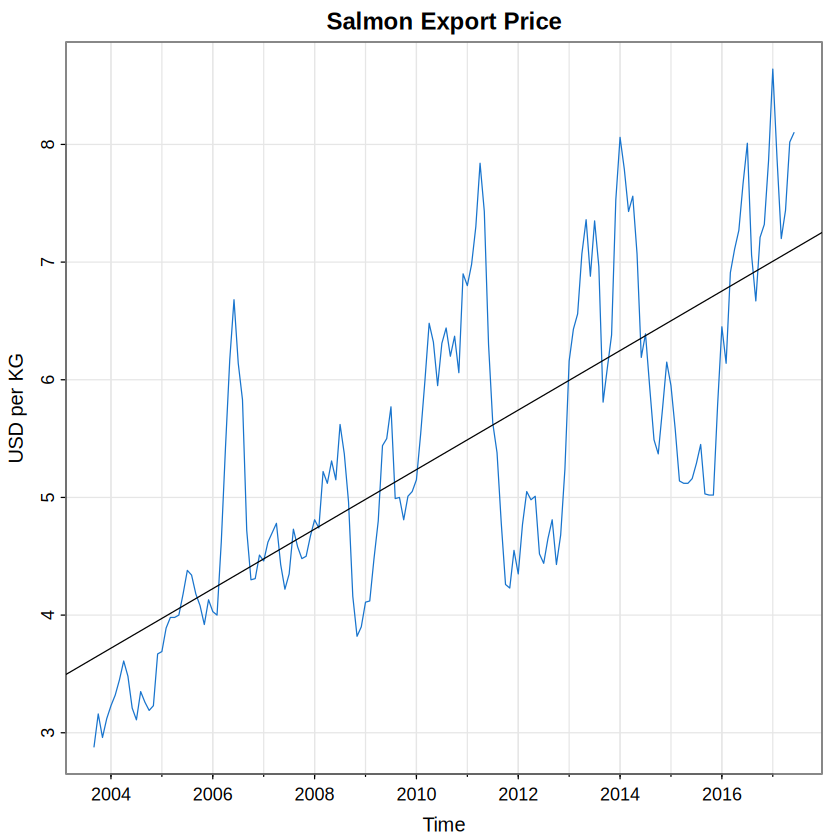

In [12]:
summary(fit_salmon <- lm(salmon ~ time(salmon), na.action=NULL))
tsplot(salmon, col=4, ylab="USD per KG", main="Salmon Export Price")
abline(fit_salmon)

cat("Slope (USD/kg per year):", coef(fit_salmon)[2], "\n")
cat("Approximate 12-month price change from fitted trend:", coef(fit_salmon)[2], "\n")
cat("R-squared:", summary(fit_salmon)$r.squared, "\n")

**Output interpretation.** The executed output gives an estimated slope of **0.25290**, slope standard error about **0.0171**, $t≈14.8$, and $R^2=0.57062$. A slope of $0.25290$ indicates an average fitted increase of about **25.3 US cents per kg per year**. $R^2=0.5706$ indicates that the fitted linear time trend accounts for approximately **57.1% of the in-sample variation** around the sample mean; it does not mean that time caused 57.1% of the price change.

**Graph.** Horizontal axis: calendar year; vertical axis: salmon price (USD/kg). The line captures the overall upward tendency, while substantial departures from the line suggest additional temporal structure. A small OLS $p$-value cannot by itself validate uncertainty estimates when regression residuals remain serially correlated. The large negative intercept results from coding time near 2003–2017, so it should not be interpreted as an economically meaningful price at year zero.

## 3. Regression accuracy, statistical tests, and model selection

For $q$ predictors and an intercept, the residual degrees of freedom are $n-(q+1)$:

$$
\mathrm{SSE}=\sum_{t=1}^n(x_t-\hat{x}_t)^2,\qquad
\mathrm{MSE}=\frac{\mathrm{SSE}}{n-(q+1)},\qquad
\hat\sigma_w=\sqrt{\mathrm{MSE}}.
$$

- **SSE**: total squared discrepancy between observed and fitted responses; smaller values mean better *in-sample* fit for the same response data.
- **MSE**: SSE adjusted for residual degrees of freedom.
- **Residual standard error**: estimated error size in the **original response units**, assuming the regression error model is appropriate.
- **Standard error of a coefficient**: estimated uncertainty in a particular $\hat\beta_j$.

To test $H_0:\beta_j=0$:

$$
t_j=\frac{\hat\beta_j-0}{\operatorname{se}(\hat\beta_j)},\qquad
\mathrm{df}=n-q-1.
$$

For comparing **nested** reduced and full models:

$$
F=\frac{(\mathrm{SSE}_{\mathrm{reduced}}-\mathrm{SSE}_{\mathrm{full}})/(q-r)}{\mathrm{SSE}_{\mathrm{full}}/(n-q-1)},
$$

where $r$ and $q$ are the numbers of non-intercept predictors in the reduced and full models. Under the usual normal, independent, constant-variance error assumptions, this statistic follows an $F_{q-r,n-q-1}$ distribution under the null hypothesis that the excluded coefficients are zero.

$$
R^2=1-\frac{\mathrm{SSE}}{\mathrm{SST}},\qquad
\mathrm{SST}=\sum_{t=1}^n(x_t-\bar x)^2.
$$

**Parsimony** means balancing a good fit against unnecessary model complexity. The book reports the following per-observation criteria with $k$ regression coefficients (including the intercept):

$$
\hat\sigma_k^2=\frac{\mathrm{SSE}(k)}{n},\qquad
\mathrm{AIC}_{\mathrm{book}}=\log\hat\sigma_k^2+\frac{n+2k}{n},
$$

$$
\mathrm{AICc}_{\mathrm{book}}=\log\hat\sigma_k^2+\frac{n+k}{n-k-2},\qquad
\mathrm{BIC}_{\mathrm{book}}=\log\hat\sigma_k^2+\frac{k\log n}{n}.
$$

The **lower** value is preferred **among comparable candidate models fit to the same observations and response**. AIC rewards predictive fit subject to a complexity penalty; BIC penalizes complexity more strongly as $n$ grows. These are the book's scaled criteria and differ from raw `AIC()` / `BIC()` output by scale or additive terms. Parameter-count conventions also affect AICc, so use one consistent convention across candidate models.

In [13]:
n_salmon = length(resid(fit_salmon))
k_salmon = length(coef(fit_salmon))
sse_salmon = sum(resid(fit_salmon)^2)
mse_salmon = sse_salmon/(n_salmon-k_salmon)
c(n=n_salmon, k=k_salmon, SSE=sse_salmon,
  MSE=mse_salmon, residual_sd=sqrt(mse_salmon),
  R_squared=summary(fit_salmon)$r.squared)

n           k         SSE         MSE residual_sd   R_squared 
  166.00000     2.00000   127.39383     0.77679     0.88136     0.57062

**Interpretation.** `SSE` and `MSE` measure different aspects of the remaining in-sample errors: SSE grows with the number of observations; MSE adjusts for the model's residual degrees of freedom. Compare `residual_sd` with the scale of salmon prices to judge typical unexplained variation, but remember that it is **not** the cross-validated forecast error.

## 4. Mortality, temperature, and particulate pollution

**Exploratory data analysis (EDA)** checks patterns before selecting a regression form. **Confounding** occurs when another associated variable may distort a coefficient's interpretation. **Collinearity** means predictors have a strong linear relationship, potentially making individual coefficients unstable. **Nonlinearity** means the response–predictor relation is not adequately represented by a straight line.

The series are approximately weekly, with 508 smoothed observations in the chapter.

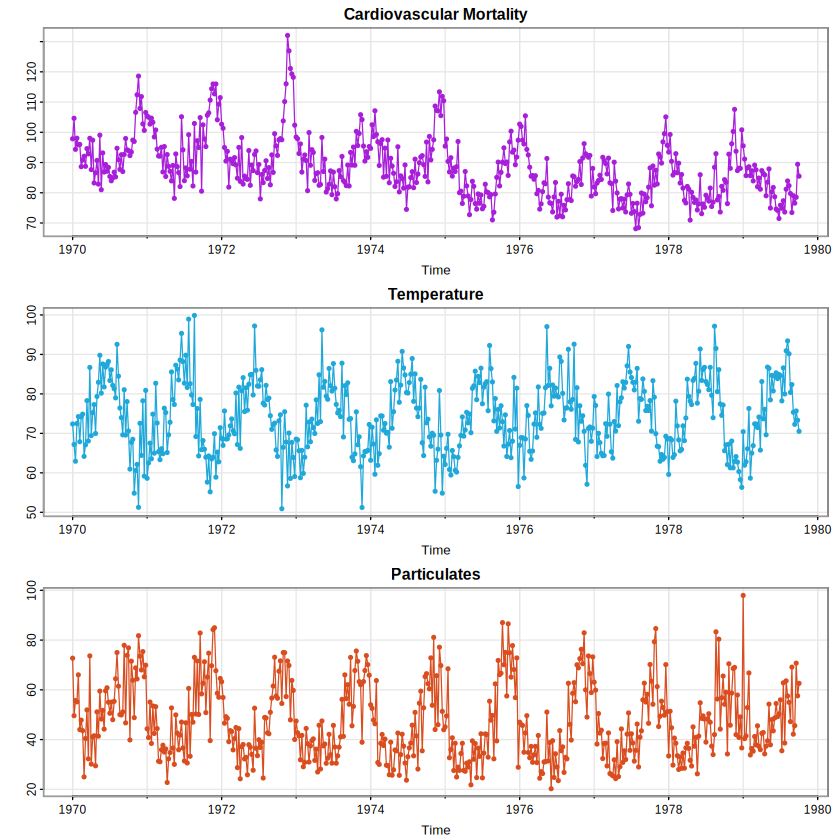

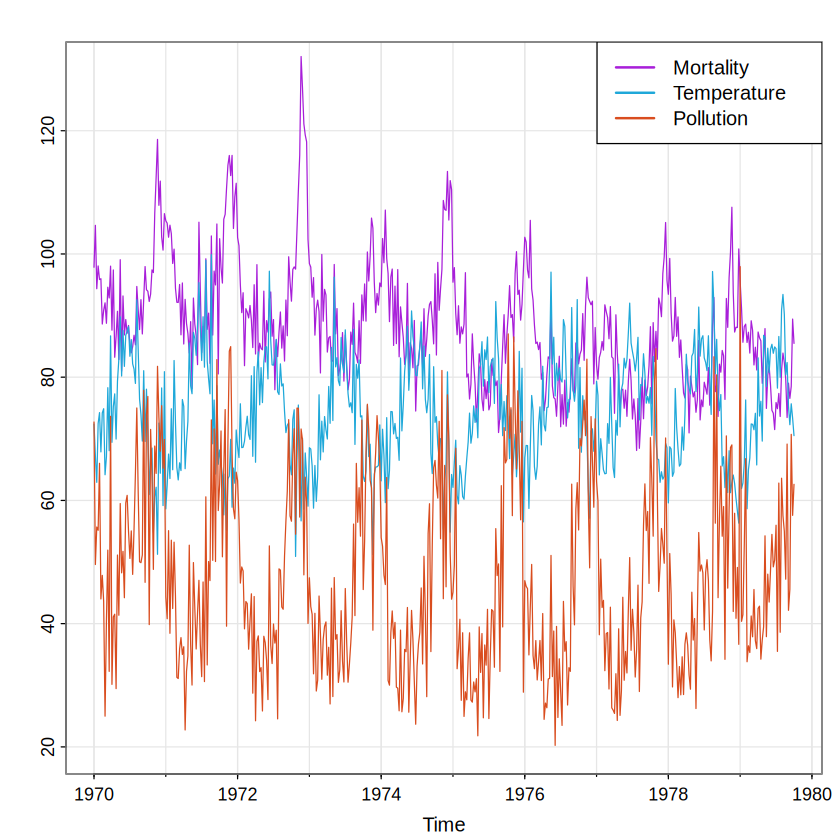

In [14]:
culer = c(rgb(.66,.12,.85), rgb(.12,.66,.85), rgb(.85,.30,.12))
par(mfrow=c(3,1))
tsplot(cmort, main="Cardiovascular Mortality", col=culer[1], type="o", pch=19, ylab="")
tsplot(tempr, main="Temperature", col=culer[2], type="o", pch=19, ylab="")
tsplot(part, main="Particulates", col=culer[3], type="o", pch=19, ylab="")
par(mfrow=c(1,1))
tsplot(cmort, main="", ylab="", ylim=c(20,130), col=culer[1])
lines(tempr, col=culer[2]); lines(part, col=culer[3])
legend("topright", legend=c("Mortality","Temperature","Pollution"),
       lty=1, lwd=2, col=culer, bg="white")

**Graph interpretation.** The first three panels have a shared calendar-time axis but distinct vertical scales; the combined plot is useful for comparing the timing of peaks and troughs, **not** the magnitudes of variables measured in different units. Mortality and temperature tend to move inversely over much of the period; particulate peaks sometimes coincide with higher mortality. Co-movement is not proof of causation. Seasonality and long-term trend can generate spurious visual associations.

,Mortality,Temperature,Particulates
Mortality,1.000,-0.439,0.444
Temperature,-0.439,1.000,-0.017
Particulates,0.444,-0.017,1.000


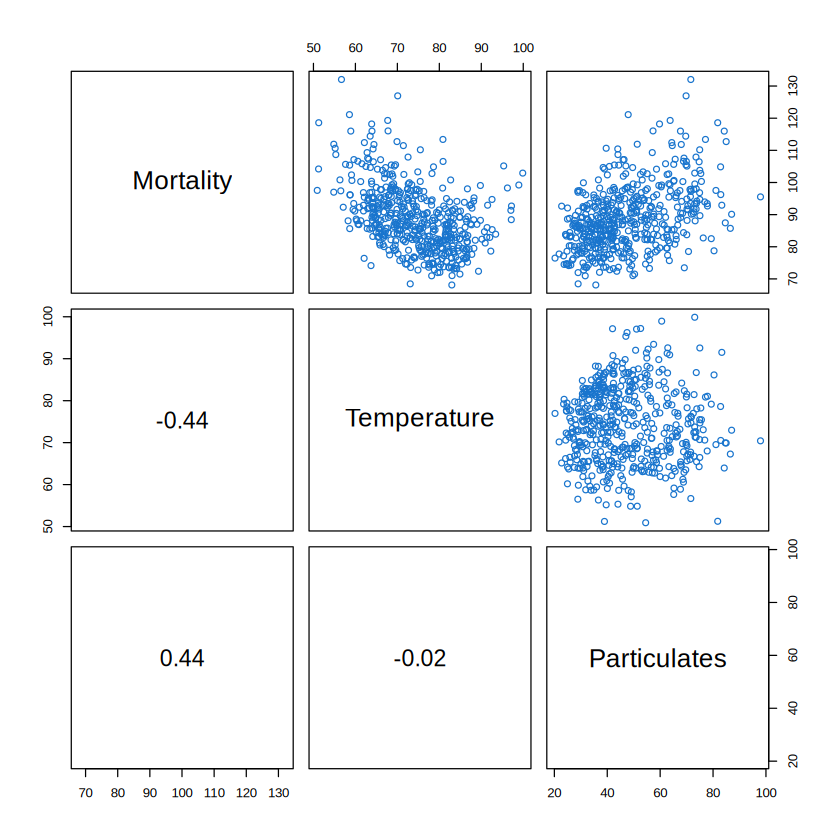

In [15]:
panel.cor <- function(x, y, ...){
  usr <- par("usr"); on.exit(par(usr=usr))
  par(usr=c(0,1,0,1))
  r <- round(cor(x,y), 2)
  text(.5,.5,r,cex=1.75)
}
pairs(cbind(Mortality=cmort, Temperature=tempr, Particulates=part),
      col="dodgerblue3", lower.panel=panel.cor)
round(cor(cbind(Mortality=as.numeric(cmort),
                Temperature=as.numeric(tempr),
                Particulates=as.numeric(part))), 3)

**Scatterplot-matrix interpretation.** Each off-diagonal scatterplot compares two variables; the lower-panel number is their sample Pearson correlation. The computed correlations are **−0.439** for mortality–temperature, **+0.444** for mortality–particulates, and **−0.017** for temperature–particulates. A low linear correlation between temperature and pollution helps separate their regression contributions. The temperature–mortality scatter still bends upward at temperature extremes, so a single Pearson coefficient obscures its curvature. These are descriptive associations, not causal effects.

### Centering temperature and fitting nested models

**Centering** subtracts the sample mean to make the linear and quadratic terms less collinear. Let $T_c=T_t-\bar T$ and $P_t$ be pollution; $M_t$ is mortality.

$$
\begin{aligned}
M_t&=\beta_0+\beta_1t+w_t &&\text{trend only},\\
M_t&=\beta_0+\beta_1t+\beta_2T_c+w_t &&\text{linear temperature},\\
M_t&=\beta_0+\beta_1t+\beta_2T_c+\beta_3T_c^2+w_t &&\text{quadratic temperature},\\
M_t&=\beta_0+\beta_1t+\beta_2T_c+\beta_3T_c^2+\beta_4P_t+w_t &&\text{full model}.
\end{aligned}
$$

$\beta_3>0$ allows a U-shaped dependence on temperature. At temperature $T$ the **marginal model slope** is $\partial\hat M/\partial T=\hat\beta_2+2\hat\beta_3(T-\bar T)$; $\beta_2$ is the slope only at $T=\bar T$.

[1] 0.99721

[1] 0.076179

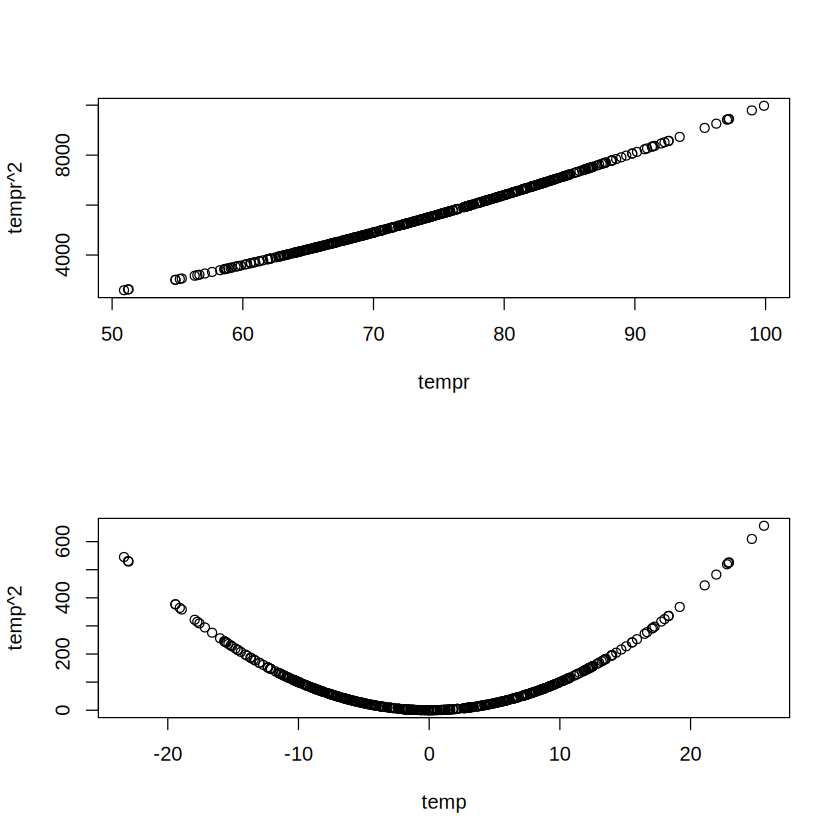

In [16]:
par(mfrow=c(2,1))
plot(tempr, tempr^2)
cor(tempr, tempr^2)
temp = tempr-mean(tempr)
plot(temp, temp^2)
cor(temp, temp^2)
par(mfrow=c(1,1))

**Output interpretation.** Raw $T$ and $T^2$ have correlation approximately **0.9972** in this dataset; centered $T_c$ and $T_c^2$ have correlation approximately **0.0762**. This is a property of these predictors and their observed distribution; centering does **not** remove every possible form of multicollinearity and does not change the fitted polynomial curve when the intercept and lower-order terms are included.

In [17]:
trend = time(cmort)
temp2 = temp^2
m1 = lm(cmort ~ trend, na.action=NULL)
m2 = lm(cmort ~ trend + temp, na.action=NULL)
m3 = lm(cmort ~ trend + temp + temp2, na.action=NULL)
fit = lm(cmort ~ trend + temp + temp2 + part, na.action=NULL)
summary(fit)
summary(aov(fit))
summary(aov(lm(cmort ~ cbind(trend, temp, temp2, part))))

# Use exactly the same sample and response for every comparison.
fits = list(Trend=m1, LinearTemp=m2, QuadraticTemp=m3, Full=fit)
metrics = t(sapply(fits, function(model){
  n = length(resid(model)); k = length(coef(model))
  SSE = sum(resid(model)^2); sigma2 = SSE/n
  c(n=n, k=k, SSE=SSE, df=n-k, MSE=SSE/(n-k),
    R2=summary(model)$r.squared,
    AIC_book=log(sigma2)+(n+2*k)/n,
    AICc_book=log(sigma2)+(n+k)/(n-k-2),
    BIC_book=log(sigma2)+k*log(n)/n)
}))
round(metrics, 4)


Call:
lm(formula = cmort ~ trend + temp + temp2 + part, na.action = NULL)

Residuals:
    Min      1Q  Median      3Q     Max 
-19.076  -4.215  -0.488   3.744  29.245 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  2.83e+03   2.00e+02   14.19  < 2e-16 ***
trend       -1.40e+00   1.01e-01  -13.82  < 2e-16 ***
temp        -4.72e-01   3.16e-02  -14.94  < 2e-16 ***
temp2        2.26e-02   2.83e-03    7.99  9.3e-15 ***
part         2.55e-01   1.89e-02   13.54  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.39 on 503 degrees of freedom
Multiple R-squared:  0.595,	Adjusted R-squared:  0.592 
F-statistic:  185 on 4 and 503 DF,  p-value: <2e-16


             Df Sum Sq Mean Sq F value Pr(>F)    
trend         1  10667   10667   261.6 <2e-16 ***
temp          1   8607    8607   211.1 <2e-16 ***
temp2         1   3429    3429    84.1 <2e-16 ***
part          1   7476    7476   183.4 <2e-16 ***
Residuals   503  20508      41                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                                 Df Sum Sq Mean Sq F value Pr(>F)    
cbind(trend, temp, temp2, part)   4  30178    7545     185 <2e-16 ***
Residuals                       503  20508      41                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

,n,k,SSE,df,MSE,R2,AIC_book,AICc_book,BIC_book
Trend,508,2,40020,506,79.091,0.2104,5.3745,5.3786,4.3912
LinearTemp,508,3,31413,505,62.204,0.3802,5.1363,5.1404,4.1613
QuadraticTemp,508,4,27985,504,55.525,0.4479,5.0247,5.0288,4.0580
Full,508,5,20508,503,40.772,0.5954,4.7178,4.7221,3.7594


**Model comparison.** Computed $R^2$ values increase approximately **0.21 → 0.38 → 0.45 → 0.60**, while SSE falls approximately **40,020 → 31,413 → 27,985 → 20,508**. The full model has the lowest calculated AIC, AICc, and BIC among these candidates. The displayed `BIC_book` metric uses the reduced expression given in the reference; its **3.7594** is on a different additive scale from `BIC(fit)/num-log(2*pi)` (**4.7717**). Both rank these four models in the same order, but do not compare their values directly without using a consistent definition. These are *in-sample* fit measures, and adding regressors always weakly decreases SSE. The penalties in AIC/AICc/BIC partly account for model size; they do not prove causation or correct dependence assumptions.

For the full model, the chapter reports coefficients approximately:

$$
\hat M_t=2831.5-1.396t-0.472(T_t-74.26)+0.023(T_t-74.26)^2+0.255P_t.
$$

Here $t$ is in **years** (`time(cmort)`), so the fitted linear trend is about $-1.396$ mortality units per year, holding temperature and pollution terms fixed. The estimated pollution effect $+0.255$ means $0.255$ more mortality units per one-unit increase in particulate pollution **conditional on the model variables**, not proof of a causal effect. Because the temperature relation is quadratic, interpreting $-0.472$ as the effect of a one-degree rise at *every* temperature would be incorrect.

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,506,40020,NA,NA,NA,NA
2,503,20508,3,19511,159.52,1.1942e-72


[1] 4.7217

[1] 4.7717

[1]  0.34  0.44  0.28  0.28  0.16  0.12  0.07  0.01  0.03 -0.05 -0.02  0.00
[13] -0.04 -0.02  0.01 -0.05 -0.01 -0.03 -0.06 -0.03 -0.03 -0.05  0.00 -0.02
[25] -0.01 -0.05  0.03 -0.11 -0.02 -0.10 -0.02 -0.09 -0.03 -0.10 -0.08 -0.10

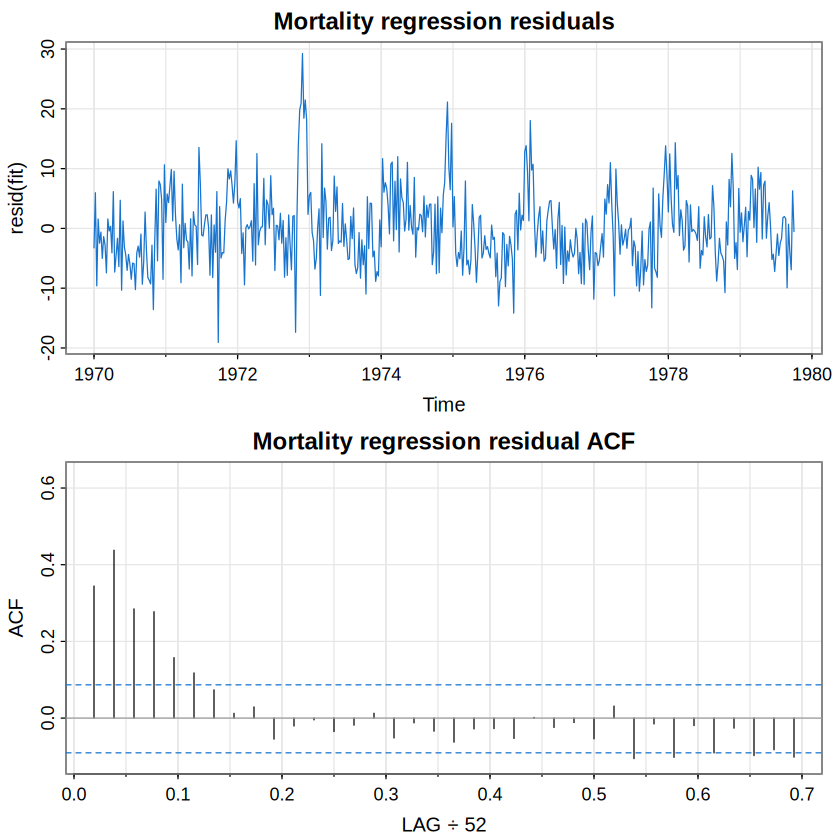

In [18]:
# Nested-model F test: trend only versus full regression
anova(m1, fit)
num = length(cmort)
AIC(fit)/num - log(2*pi)
BIC(fit)/num - log(2*pi)

# Residual dependence: an assumption check for OLS inference
par(mfrow=c(2,1))
tsplot(resid(fit), col=4, main="Mortality regression residuals")
acf1(resid(fit), 36, main="Mortality regression residual ACF")
par(mfrow=c(1,1))

**Interpretation.** The nested-model F test asks whether adding temperature, squared temperature, and pollution improves fit relative to the trend-only model under classical OLS error assumptions. The executed nested-model test gives **$F=159.52$** on **3 and 503** degrees of freedom ($p\approx1.19\times10^{-72}$), showing a substantial *in-sample* reduction in SSE under the classical test assumptions. The residual ACF is about **0.34 at lag 1** and **0.44 at lag 2**, so the errors are not behaving like white noise. If the residual time plot displays runs, or the residual ACF shows substantial nonzero-lag spikes, the iid/white-noise error assumption is not supported. Conventional OLS standard errors and F-test significance should then be treated cautiously; the chapter postpones regression with correlated errors to a later section.

## 5. Lagged regression: Recruitment and the Southern Oscillation Index

A **lag** means using a past observation: $S_{t-6}$ is SOI six months before Recruitment $R_t$. Properly matching time indices is essential.

$$
R_t=\beta_0+\beta_1S_{t-6}+w_t.
$$

A negative slope means larger earlier SOI readings are associated with lower current Recruitment **under the linear model**. Lagged association alone does not establish a causal delay.


Call:
lm(formula = rec ~ soiL6, data = fish, na.action = NULL)

Residuals:
   Min     1Q Median     3Q    Max 
-65.19 -18.23   0.35  16.58  55.79 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)    65.79       1.09    60.5   <2e-16 ***
soiL6         -44.28       2.78   -15.9   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 22.5 on 445 degrees of freedom
Multiple R-squared:  0.363,	Adjusted R-squared:  0.362 
F-statistic:  254 on 1 and 445 DF,  p-value: <2e-16


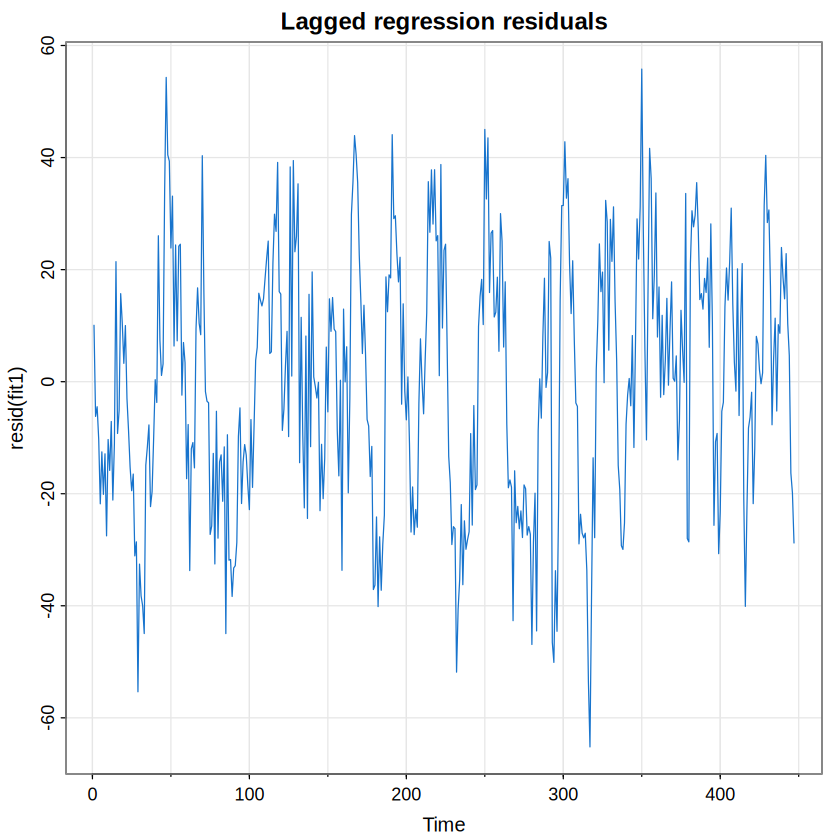

[1]  0.72  0.63  0.51  0.38  0.25  0.16  0.08 -0.01 -0.05 -0.11 -0.15 -0.18
[13] -0.20 -0.24 -0.24 -0.21 -0.20 -0.19 -0.13 -0.06 -0.02  0.03  0.06  0.07
[25]  0.08  0.07  0.07  0.03  0.00 -0.05 -0.05 -0.05 -0.07 -0.05 -0.02  0.00


Time series regression with "ts" data:
Start = 1950(7), End = 1987(9)

Call:
dynlm(formula = rec ~ L(soi, 6))

Residuals:
   Min     1Q Median     3Q    Max 
-65.19 -18.23   0.35  16.58  55.79 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)    65.79       1.09    60.5   <2e-16 ***
L(soi, 6)     -44.28       2.78   -15.9   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 22.5 on 445 degrees of freedom
Multiple R-squared:  0.363,	Adjusted R-squared:  0.362 
F-statistic:  254 on 1 and 445 DF,  p-value: <2e-16


Coefficient difference (ts.intersect vs dynlm):
(Intercept)       soiL6 
          0           0 


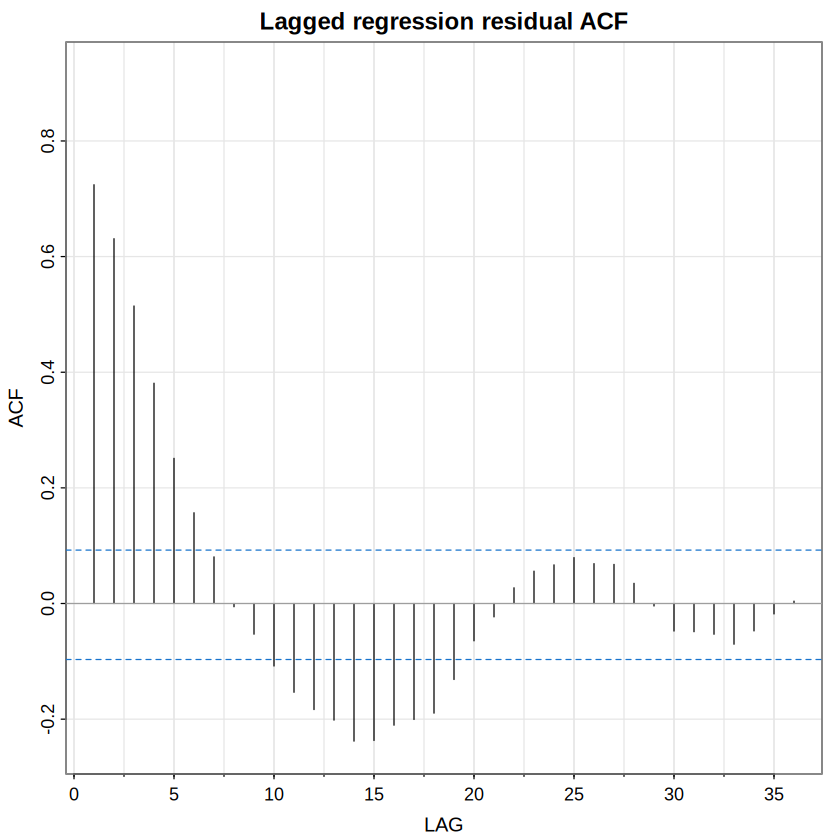

In [19]:
fish = ts.intersect(rec, soiL6=lag(soi,-6))
summary(fit1 <- lm(rec ~ soiL6, data=fish, na.action=NULL))
tsplot(resid(fit1), col=4, main="Lagged regression residuals")
acf1(resid(fit1), 36, main="Lagged regression residual ACF")
summary(fit2 <- dynlm(rec ~ L(soi,6)))
cat("Coefficient difference (ts.intersect vs dynlm):\n")
print(coef(fit1)-coef(fit2))

**Output interpretation.** Executed fitted relation: $\hat R_t\approx65.79-44.28S_{t-6}$, with slope SE **2.78**, residual SD **22.5**, and $R^2\approx0.3629$. For a one-unit higher SOI reading six months earlier, predicted Recruitment is **44.28 units lower** on average under this specification. The intercept predicts Recruitment at SOI $=0$. The fitted linear relation leaves about 63.7% of in-sample variability unexplained. The residual ACF starts at approximately **0.72** at lag 1 and **0.63** at lag 2, strongly contradicting white-noise errors, and a later nonlinear analysis shows the slope is not uniform across SOI values. `dynlm()` provides an equivalent time-aligned fit for this example.

## 6. Detrending, differencing, and stationarity

A time series is **weakly stationary** if its mean and variance are constant over time and its covariance depends only on lag. **Trend stationary** means the series fluctuates in a stationary way around a deterministic trend:

$$
x_t=\mu_t+y_t,\qquad \hat y_t=x_t-\hat\mu_t.
$$

**Detrending** estimates and subtracts $\mu_t$ (for example, an OLS trend). **Differencing** instead subtracts the preceding observation:

$$
\nabla x_t=x_t-x_{t-1}=(1-B)x_t,\qquad Bx_t=x_{t-1}.
$$

Here $B$ is the **backshift operator** and $\nabla$ is the difference operator. Second differencing gives

$$
\nabla^2x_t=(1-B)^2x_t=x_t-2x_{t-1}+x_{t-2}.
$$

For a random-walk trend $\mu_t=\delta+\mu_{t-1}+w_t$ with independent stationary remainder $y_t$:

$$
\nabla x_t=\delta+w_t+y_t-y_{t-1},\qquad
\gamma_{\nabla y}(h)=2\gamma_y(h)-\gamma_y(h+1)-\gamma_y(h-1).
$$

This transformed series is stationary under the stated assumptions. Differencing removes a stochastic trend in this model, while detrending with a straight line generally does not.

[1]  0.89  0.72  0.56  0.42  0.29  0.20  0.14  0.10  0.08  0.06  0.01 -0.07
[13] -0.20 -0.33 -0.43 -0.50 -0.54 -0.58 -0.56 -0.50 -0.44 -0.35 -0.26 -0.19
[25] -0.17 -0.17 -0.17 -0.17 -0.13 -0.09  0.01  0.14  0.27  0.37  0.45  0.48
[37]  0.42  0.34  0.27  0.21  0.17  0.14  0.14  0.15  0.16  0.14  0.10  0.05

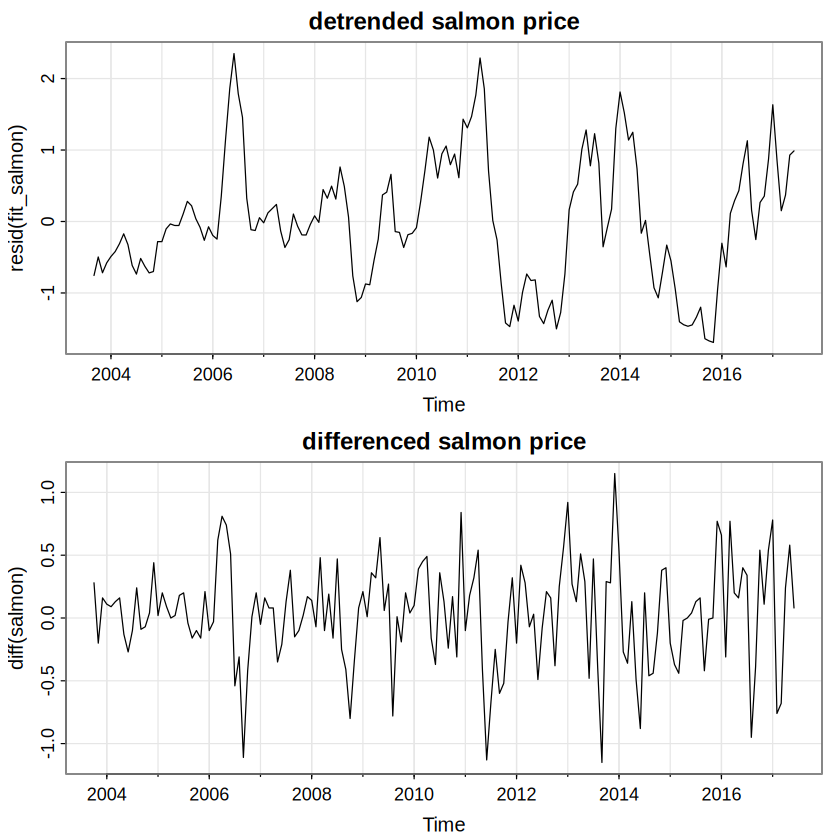

[1]  0.26 -0.02 -0.08 -0.10 -0.19 -0.11 -0.10 -0.06  0.02  0.07  0.15  0.24
[13]  0.00 -0.15 -0.14 -0.07 -0.04 -0.23 -0.15 -0.05 -0.07 -0.06  0.13  0.21
[25]  0.11 -0.01  0.00 -0.16 -0.09 -0.23 -0.10  0.04  0.12  0.09  0.23  0.34
[37]  0.08 -0.06 -0.06 -0.08 -0.07 -0.09 -0.06  0.06  0.10  0.06  0.04  0.12

,variance,lag1
Detrended,0.77208,0.88736
Differenced,0.16546,0.26286


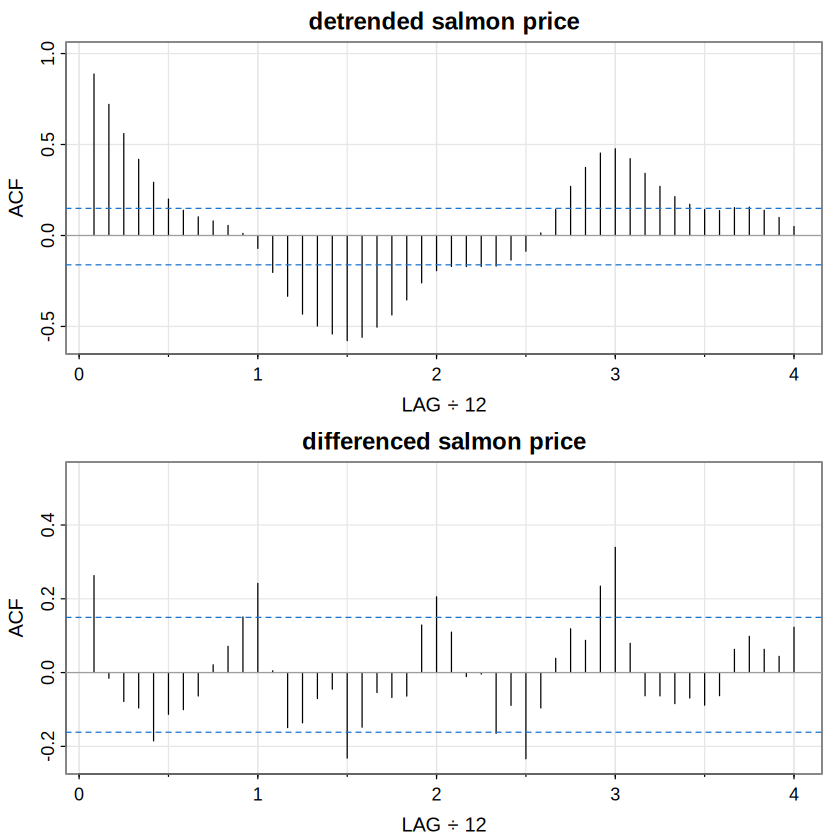

In [20]:
fit_salmon = lm(salmon ~ time(salmon), na.action=NULL)
par(mfrow=c(2,1))
tsplot(resid(fit_salmon), main="detrended salmon price")
tsplot(diff(salmon), main="differenced salmon price")
par(mfrow=c(2,1))
acf1(resid(fit_salmon), 48, main="detrended salmon price")
acf1(diff(salmon), 48, main="differenced salmon price")
par(mfrow=c(1,1))

# Compare variance and short-lag ACF numerically
rbind(Detrended=c(variance=var(as.numeric(resid(fit_salmon))),
                  lag1=as.numeric(acf(resid(fit_salmon), plot=FALSE, lag.max=1)$acf[2])),
      Differenced=c(variance=var(as.numeric(diff(salmon))),
                   lag1=as.numeric(acf(diff(salmon), plot=FALSE, lag.max=1)$acf[2])))

**Graph interpretation.** The upper time plot contains **deviations from the fitted price trend** (units: USD/kg); the lower shows **month-to-month price changes** (also USD/kg). These are different quantities and need not have similar variances. The ACF panels have lag axes in **years** for a monthly `ts` object, so an ACF location at 1 represents 12 monthly lags, not one month. The sample lag-1 ACF is **0.88736** for the detrended series and **0.26286** for the differenced series. The detrended ACF has a slower oscillation, while the differenced series displays recurring annual-lag structure, including a positive ACF near the 12-month lag. Those are visual patterns that should be checked in the actual output. Neither a flat-looking detrended plot nor differencing automatically proves stationarity.

[1] -0.51  0.04  0.00 -0.05  0.00  0.09 -0.06 -0.06  0.13 -0.05 -0.13  0.24
[13] -0.15  0.01  0.07 -0.05 -0.02  0.03  0.05 -0.08  0.03  0.00 -0.08  0.14

[1] 0.015954

[1] 0.049091

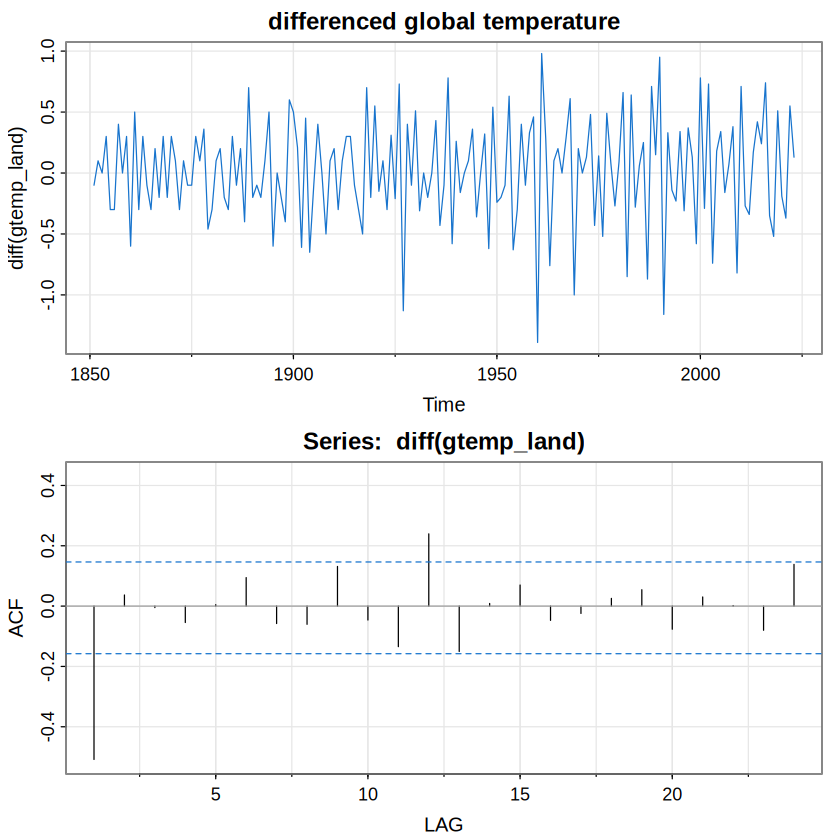

In [21]:
par(mfrow=c(2,1))
tsplot(diff(gtemp_land), col=4, main="differenced global temperature")
acf1(diff(gtemp_land))
par(mfrow=c(1,1))
mean(diff(gtemp_land))
mean(window(diff(gtemp_land), start=1980))

**Output interpretation.** The executed dataset gives mean annual differences of **0.015954 °C/year** over the full available series and **0.049091 °C/year** from 1980 onward. Multiplication by 100 gives **1.60 °C/century** and **4.91 °C/century** as simple rate equivalents, **not forecasts**. The reference text reports older values (0.0143 and 0.0329), so the difference is consistent with using different versions or coverage of the temperature dataset. Use the values printed by the running notebook when interpreting its figures. A relatively weak lag-1 ACF after differencing is compatible with a random-walk-with-drift approximation, but does not establish the model by itself. The graph's x-axis is calendar year and y-axis is yearly temperature change in degrees Celsius.

## 7. Variance stabilization, logarithms, and Q–Q diagnostics

**Heteroscedasticity** means variability is not constant. For positive $x_t$, the logarithmic transform $y_t=\log x_t$ compresses large values and is often useful when fluctuations grow with the level.

The **Box–Cox transformation** generalizes the log transform:

$$
y_t=\begin{cases}
\dfrac{x_t^\lambda-1}{\lambda},&\lambda\ne0,\\[4pt]
\log x_t,&\lambda=0.
\end{cases}
$$

$\lambda$ controls the strength and direction of the power transformation. Strictly positive values are required for the standard logarithm and Box–Cox form shown. A **normal Q–Q plot** compares sample quantiles with normal-theory quantiles. Roughly straight points support approximate marginal normality; departures indicate skewness or tail differences. Marginal normality is different from stationarity or independent residual errors.

original_mean   original_sd      log_mean        log_sd 
     27.87655      20.31376       3.11799       0.63745

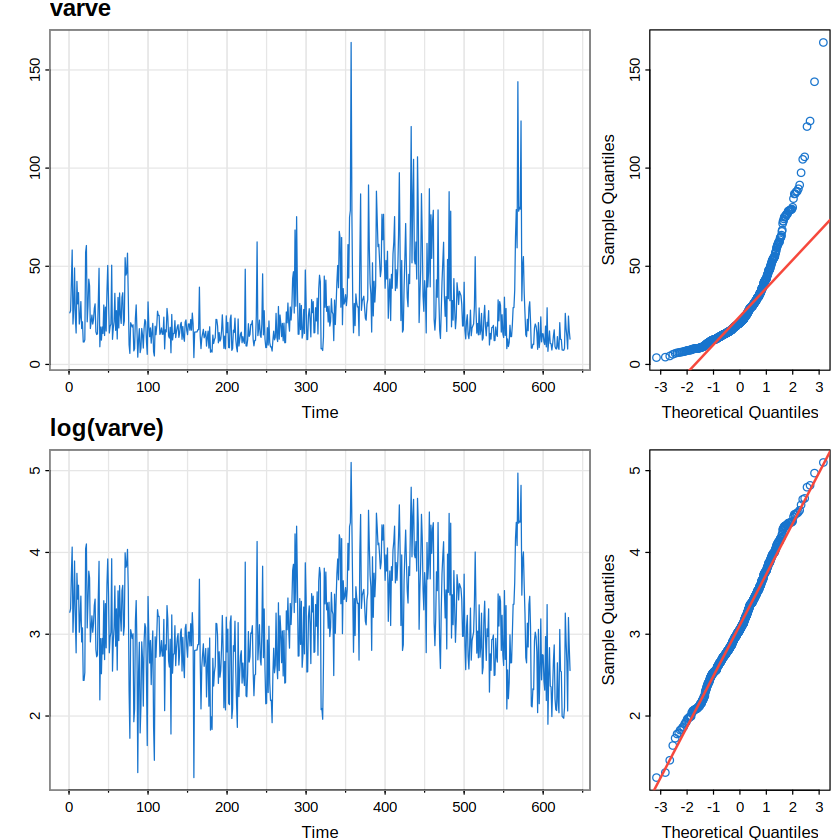

In [22]:
layout(matrix(1:4, 2), widths=c(2.5,1))
par(mgp=c(1.6,.6,0), mar=c(2,2,.5,0)+.5)
tsplot(varve, main="", ylab="", col=4, margin=0)
mtext("varve", side=3, line=.5, cex=1.2, font=2, adj=0)
tsplot(log(varve), main="", ylab="", col=4, margin=0)
mtext("log(varve)", side=3, line=.5, cex=1.2, font=2, adj=0)
qqnorm(varve, main="", col=4); qqline(varve, col=2, lwd=2)
qqnorm(log(varve), main="", col=4); qqline(log(varve), col=2, lwd=2)
layout(1)

c(original_mean=mean(varve), original_sd=sd(varve),
  log_mean=mean(log(varve)), log_sd=sd(log(varve)))

**Graph interpretation.** Left column: glacial sediment-layer thickness before and after logging, plotted against observation index. Right column: normal Q–Q plots; points nearer the reference line indicate a closer approximation to a normal *marginal* distribution. The chapter describes a reduction in level-dependent spread and improved Q–Q alignment after log transformation. The transformed vertical axis uses **log thickness**, not original thickness units; its standard deviation should not be directly compared as if it used the original units. The transformation does not establish that temporal dependence has disappeared.

## 8. Lag plots and nonlinear relationships

A **lag plot** places an observation against an earlier observation. A straight diagonal cloud suggests a linear relation; curvature in the smoothed line suggests nonlinearity. **Lowess** is a locally weighted smooth curve used here to reveal shapes that one correlation coefficient can miss.

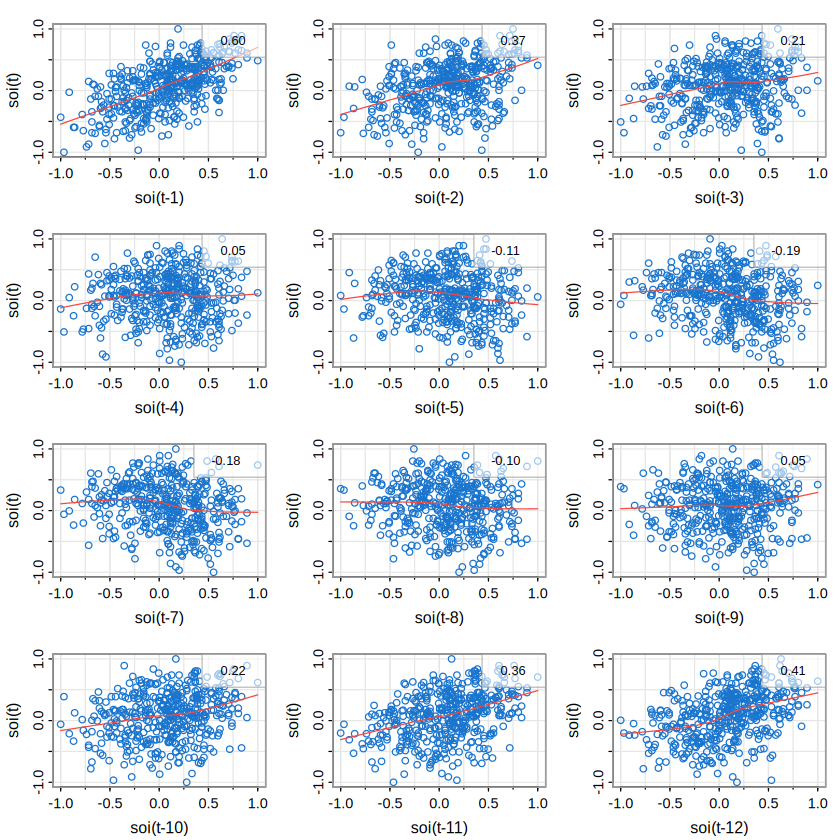

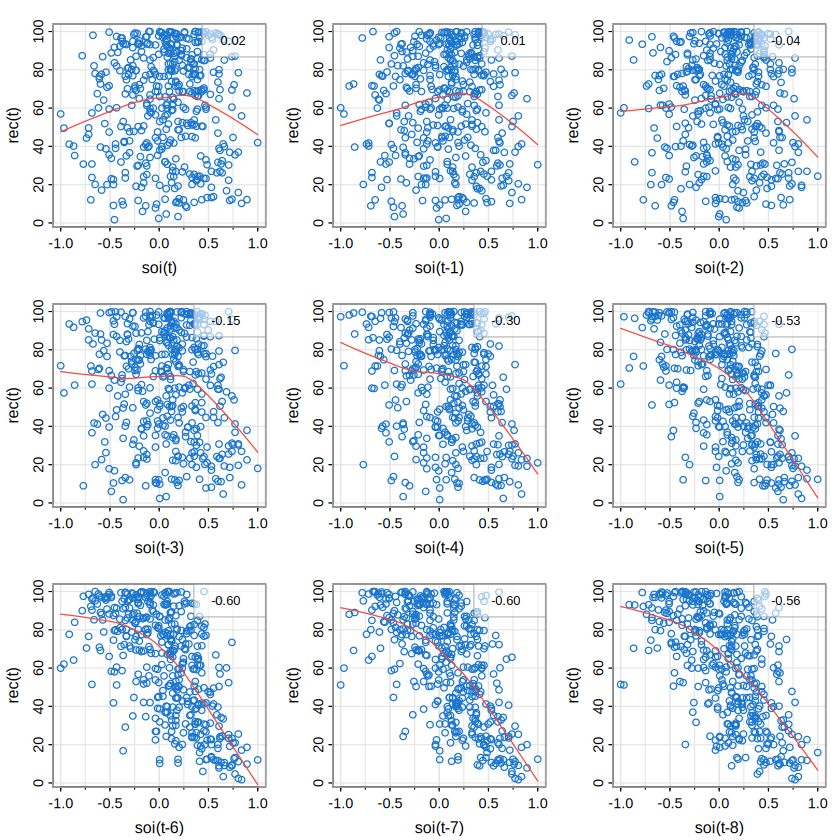

In [23]:
lag1.plot(soi, 12, col="dodgerblue3")
lag2.plot(soi, rec, 8, col="dodgerblue3")

**SOI lag-plot interpretation.** Each scatterplot's x-axis is $S_{t-h}$ and y-axis is $S_t$. The number in the corner is sample autocorrelation at that lag, while the lowess line reveals possible curvature. The chapter reports positive associations at lags 1, 2, 11, 12 and negative ones near lags 6–7, consistent with an annual oscillation.

**SOI–Recruitment lag-plot interpretation.** Each panel's x-axis is earlier SOI $S_{t-h}$ and y-axis is Recruitment $R_t$. Chapter correlations near lags 5–8 are negative (roughly −0.53 to −0.60), but the smoothed curves bend, suggesting that one straight-line slope is inadequate. The timing reflects **association with SOI measured earlier**, not established causality.

## 9. Piecewise lagged regression with a dummy-variable interaction

**Dummy variable** $D_{t-6}$ equals 1 when earlier SOI is nonnegative and 0 otherwise. An **interaction** $D_{t-6}S_{t-6}$ allows the SOI slope to differ between the two regimes.

$$
R_t=\beta_0+\beta_1S_{t-6}+\beta_2D_{t-6}+\beta_3D_{t-6}S_{t-6}+w_t.
$$

$$
E(R_t\mid S_{t-6})=
\begin{cases}
\beta_0+\beta_1S_{t-6},&S_{t-6}<0,\\
(\beta_0+\beta_2)+(\beta_1+\beta_3)S_{t-6},&S_{t-6}\ge0.
\end{cases}
$$

$\beta_2$ is the estimated intercept change at the regime boundary; $\beta_3$ is the estimated **difference in slopes** between SOI regimes. The function can have a discontinuity at zero, because these two fitted lines are not constrained to meet.


Call:
lm(formula = rec ~ soiL6 * dL6, data = fish, na.action = NULL)

Residuals:
   Min     1Q Median     3Q    Max 
-63.29 -15.82   2.22  15.79  61.79 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)    74.48       2.86   26.00  < 2e-16 ***
soiL6         -15.36       7.40   -2.08    0.039 *  
dL6            -1.14       3.71   -0.31    0.759    
soiL6:dL6     -51.24       9.52   -5.38  1.2e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 21.8 on 443 degrees of freedom
Multiple R-squared:  0.402,	Adjusted R-squared:  0.398 
F-statistic: 99.4 on 3 and 443 DF,  p-value: <2e-16


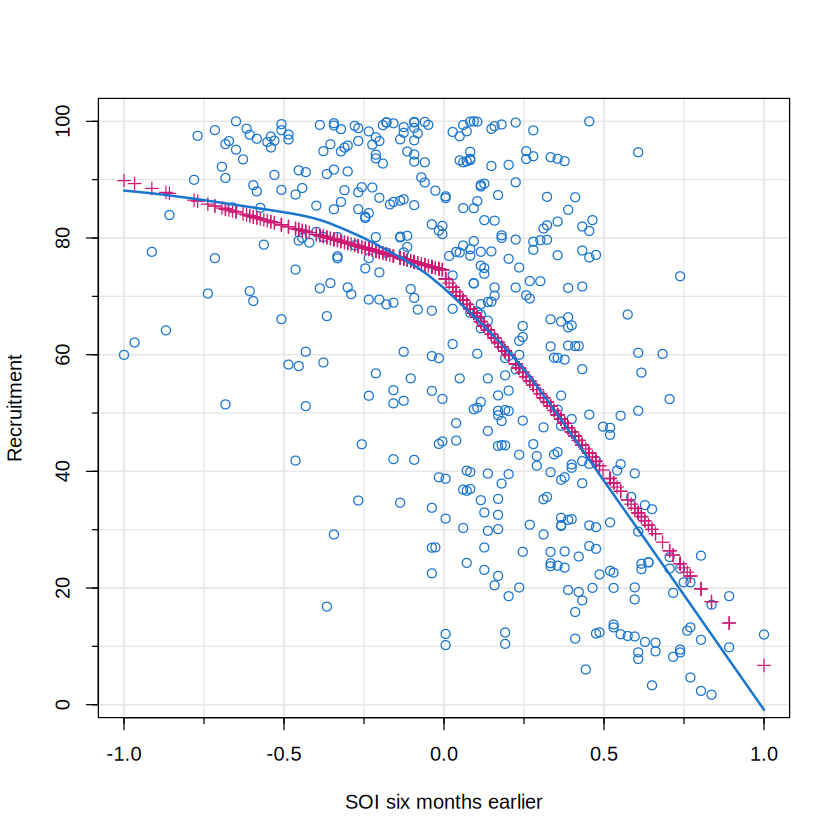

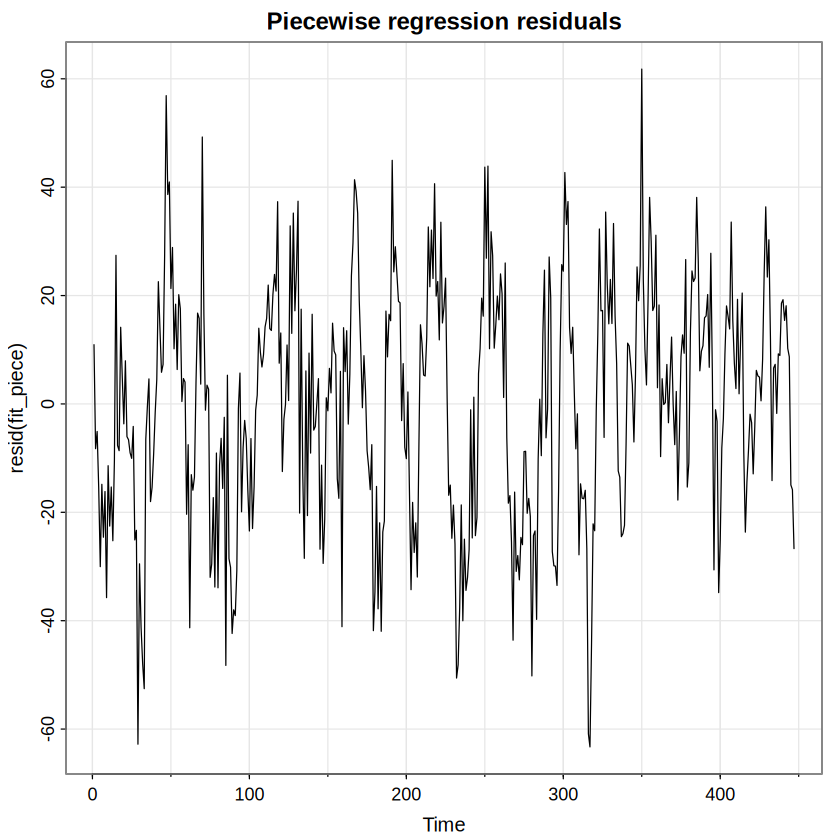

[1]  0.69  0.62  0.49  0.37  0.24  0.15  0.08  0.00 -0.03 -0.10 -0.13 -0.16
[13] -0.17 -0.23 -0.24 -0.23 -0.23 -0.22 -0.17 -0.09 -0.05  0.01  0.05  0.06
[25]  0.09  0.07  0.10  0.06  0.02 -0.02 -0.02 -0.02

slope_negative_SOI.soiL6 slope_nonnegative_SOI.soiL6 
                    -15.358                     -66.602 
                residual_sd 
                     21.839

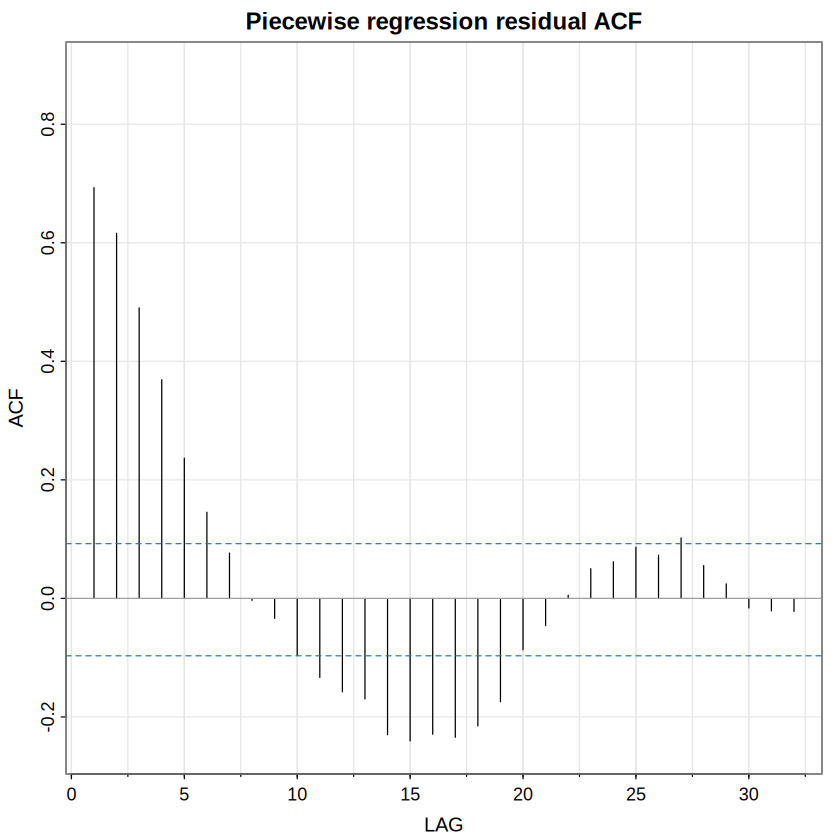

In [24]:
dummy = ifelse(soi < 0, 0, 1)
fish = as.zoo(ts.intersect(rec, soiL6=lag(soi,-6), dL6=lag(dummy,-6)))
summary(fit_piece <- lm(rec ~ soiL6*dL6, data=fish, na.action=NULL))
plot(fish$soiL6, fish$rec, panel.first=Grid(), col="dodgerblue3",
     xlab="SOI six months earlier", ylab="Recruitment")
points(fish$soiL6, fitted(fit_piece), pch=3, col=6)
lines(lowess(fish$soiL6, fish$rec), col=4, lwd=2)
tsplot(resid(fit_piece), main="Piecewise regression residuals")
acf1(resid(fit_piece), main="Piecewise regression residual ACF")

b = coef(fit_piece)
c(slope_negative_SOI=b["soiL6"],
  slope_nonnegative_SOI=b["soiL6"] + b["soiL6:dL6"],
  residual_sd=summary(fit_piece)$sigma)

**Numerical interpretation.** The executed coefficients are $\hat\beta_0\approx74.48$, $\hat\beta_1\approx-15.36$, $\hat\beta_2\approx-1.14$, and $\hat\beta_3\approx-51.24$. Therefore the estimated SOI slope is **−15.358** for negative SOI and **−66.602** ($-15.358-51.244$) for nonnegative SOI. The interaction has a small reported $p$-value (about $1.2\times10^{-7}$) under the ordinary regression error assumptions, but the residual ACF remains about **0.69 at lag 1** and **0.62 at lag 2**, making this inferential result provisional. The plot shows individual observations, crosses for fitted conditional means, and a lowess benchmark; closeness to lowess suggests improved functional shape but does not mean the regression errors are white noise.

## 10. Recovering a periodic signal by regression

A **sinusoid** is a repeating waveform; **amplitude** $A$ is its maximum distance from zero, **frequency** $\omega$ is cycles per time step, **period** is $1/\omega$, and **phase** $\phi$ shifts the wave horizontally.

$$
x_t=A\cos(2\pi\omega t+\phi)+w_t.
$$

When the frequency is known, use $\cos(a+b)=\cos a\cos b-\sin a\sin b$:

$$
x_t=\beta_1\cos(2\pi\omega t)+\beta_2\sin(2\pi\omega t)+w_t,
$$

$$
\beta_1=A\cos\phi,\quad \beta_2=-A\sin\phi,\quad
A=\sqrt{\beta_1^2+\beta_2^2},\quad
\phi=\operatorname{atan2}(-\beta_2,\beta_1).
$$

The **`atan2`** function handles the phase quadrant correctly. An intercept is omitted because the example's true signal has zero mean.


Call:
lm(formula = x ~ 0 + z1 + z2)

Residuals:
    Min      1Q  Median      3Q     Max 
-14.858  -3.853  -0.319   3.349  15.544 

Coefficients:
   Estimate Std. Error t value Pr(>|t|)    
z1   -0.744      0.327   -2.27    0.023 *  
z2   -1.995      0.327   -6.09  2.2e-09 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.18 on 498 degrees of freedom
Multiple R-squared:  0.0783,	Adjusted R-squared:  0.0746 
F-statistic: 21.1 on 2 and 498 DF,  p-value: 1.54e-09


beta1.z1           beta2.z2          amplitude   phase_radians.z2 
          -0.74425           -1.99494            2.12925            1.92787 
            period estimated_noise_sd 
          50.00000            5.17726

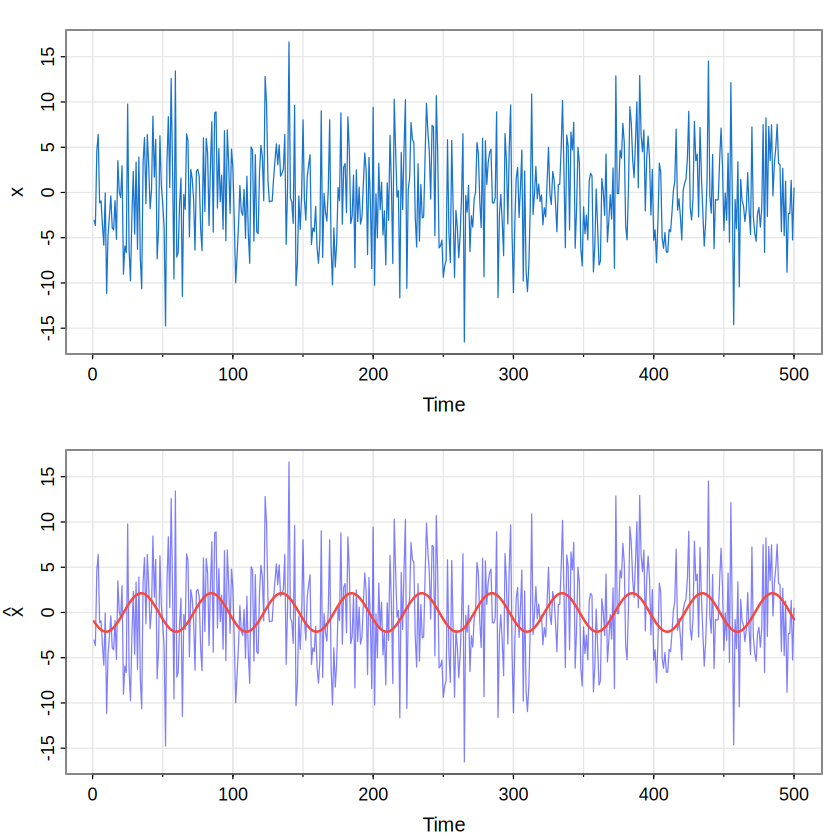

In [25]:
set.seed(90210)
x = 2*cos(2*pi*1:500/50 + .6*pi) + rnorm(500,0,5)
z1 = cos(2*pi*1:500/50)
z2 = sin(2*pi*1:500/50)
summary(fit_signal <- lm(x ~ 0 + z1 + z2))
par(mfrow=c(2,1))
tsplot(x, col=4)
tsplot(x, ylab=expression(hat(x)), col=rgb(0,0,1,.5))
lines(fitted(fit_signal), col=2, lwd=2)
par(mfrow=c(1,1))

b = coef(fit_signal)
c(beta1=b[1], beta2=b[2], amplitude=sqrt(sum(b^2)),
  phase_radians=atan2(-b[2],b[1]), period=50,
  estimated_noise_sd=summary(fit_signal)$sigma)

**Output interpretation.** The executed simulation gives $\hat\beta_1\approx-0.7442$, $\hat\beta_2\approx-1.9949$, compared with true values $2\cos(0.6\pi)\approx-0.618$ and $-2\sin(0.6\pi)\approx-1.902$. The recovered amplitude is about **2.13** and phase about **1.93 radians**, close to the true $A=2$ and $\phi=0.6\pi\approx1.885$. Estimated noise SD is about **5.18**, illustrating that a periodic component may still be detected even when noise fluctuations are larger than its amplitude. The x-axis is simulation step and y-axis is simulated signal-plus-noise value. The fitted red line isolates the estimated repeating 50-step oscillation; significance of the two basis coefficients is conditional on the specified known frequency and error assumptions.

## 11. Symmetric moving-average smoothing

A **smoother** suppresses short-term fluctuations to reveal slower changes. A **symmetric moving average** weights neighboring observations on both sides of time $t$:

$$
m_t=\sum_{j=-k}^{k}a_jx_{t-j},\qquad a_{j}=a_{-j}\ge0,\qquad \sum_{j=-k}^{k}a_j=1.
$$

For monthly SOI, the chapter uses 13 weights with half-weights at the endpoints (the months six steps before and after the center):

$$
(a_{-6},\ldots,a_6)=\frac1{12}\left(\frac12,1,1,1,1,1,1,1,1,1,1,1,\frac12\right).
$$

These weights sum to 1. The boundary observations without six neighbors on both sides become `NA` under a centered filter.

Weight sum: 1 
Original SD: 0.38275 Filtered SD: 0.18455 


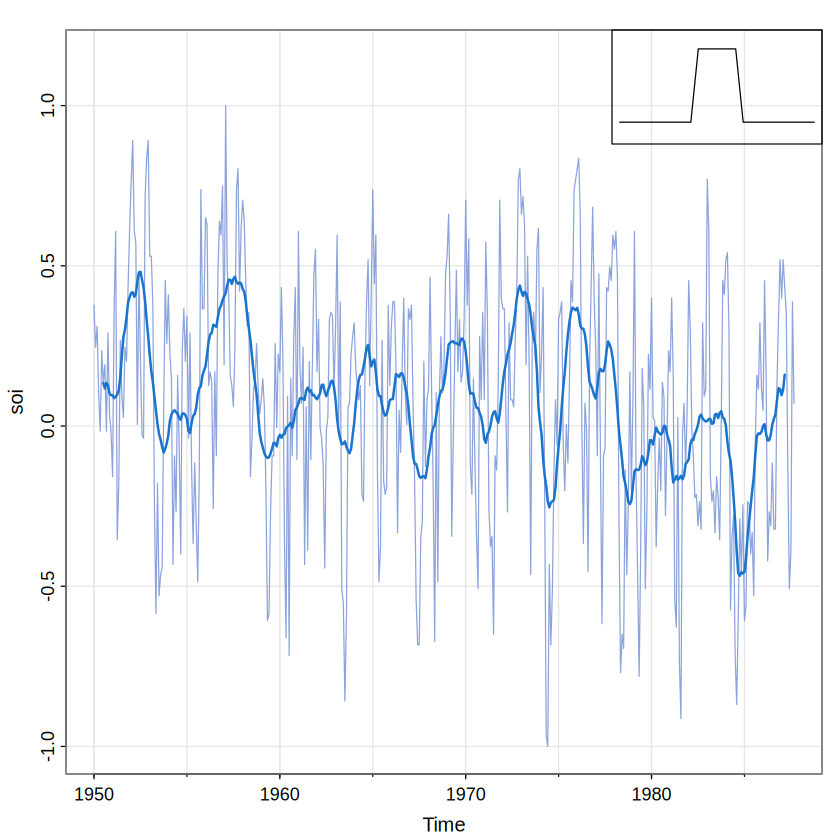

In [26]:
w = c(.5, rep(1,11), .5)/12
soif = filter(soi, sides=2, filter=w)
cat("Weight sum:", sum(w), "\n")
cat("Original SD:", sd(soi), "Filtered SD:", sd(soif, na.rm=TRUE), "\n")
tsplot(soi, col=rgb(.5,.6,.85,.9), ylim=c(-1,1.15))
lines(soif, lwd=2, col=4)
par(fig=c(.65,1,.75,1), new=TRUE)
w1 = c(rep(0,20),w,rep(0,20))
plot(w1, type="l", ylim=c(-.02,.1), xaxt="n", yaxt="n", ann=FALSE)
par(fig=c(0,1,0,1), new=FALSE)

**Graph interpretation.** The pale line is observed monthly SOI and the darker line is its smoothed estimate. The insert shows the nonzero moving-average weights. The annual oscillation is attenuated by averaging across about one year, making slower multi-year changes more visible. The printed SD falls from **0.38275** for the original observations to **0.18455** for the filtered values (excluding missing boundary points), quantifying the smoothing, but **reduced SD does not prove improved forecasting** and may suppress meaningful short-lived variation.

## 12. Kernel smoothing

A **kernel** assigns larger weight to observations near the target time. A normalized Gaussian kernel smoother uses

$$
m(t)=\sum_{i=1}^n w_i(t)x_i,\qquad
w_i(t)=\frac{K((t-t_i)/b)}{\sum_{k=1}^nK((t-t_k)/b)},\qquad
K(u)=\exp(-u^2/2).
$$

Here $b$ is the **bandwidth**: larger $b$ creates a smoother fit and suppresses finer fluctuations. Note that the kernel expression defines a scale parameter; R's `ksmooth(..., bandwidth=...)` uses its documented bandwidth convention, so treat its argument as a smoothing control rather than automatically equating it numerically to a Gaussian SD.

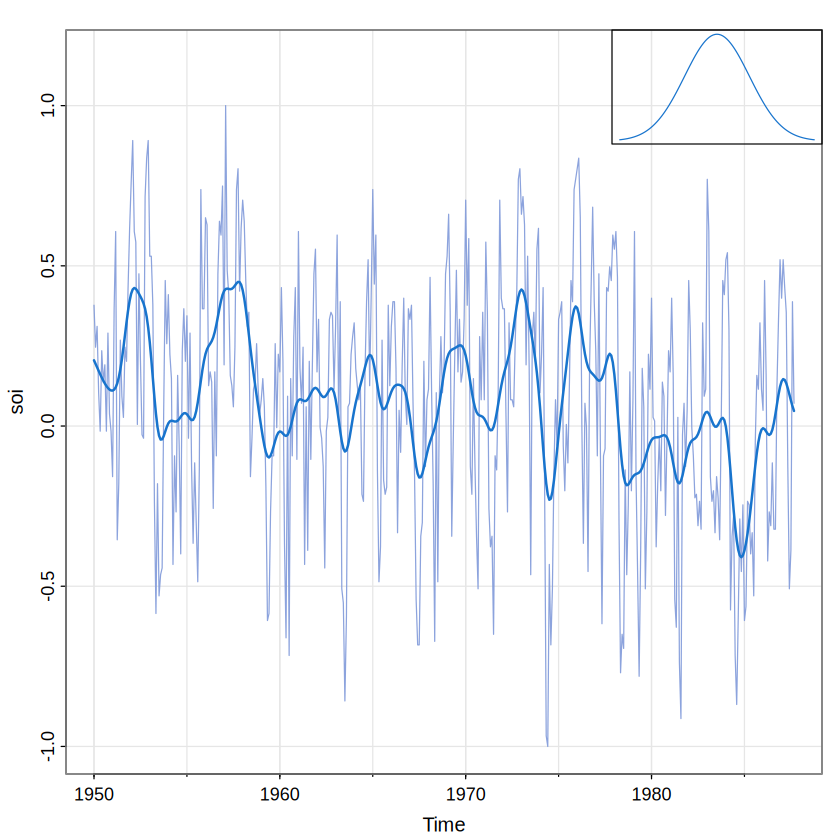

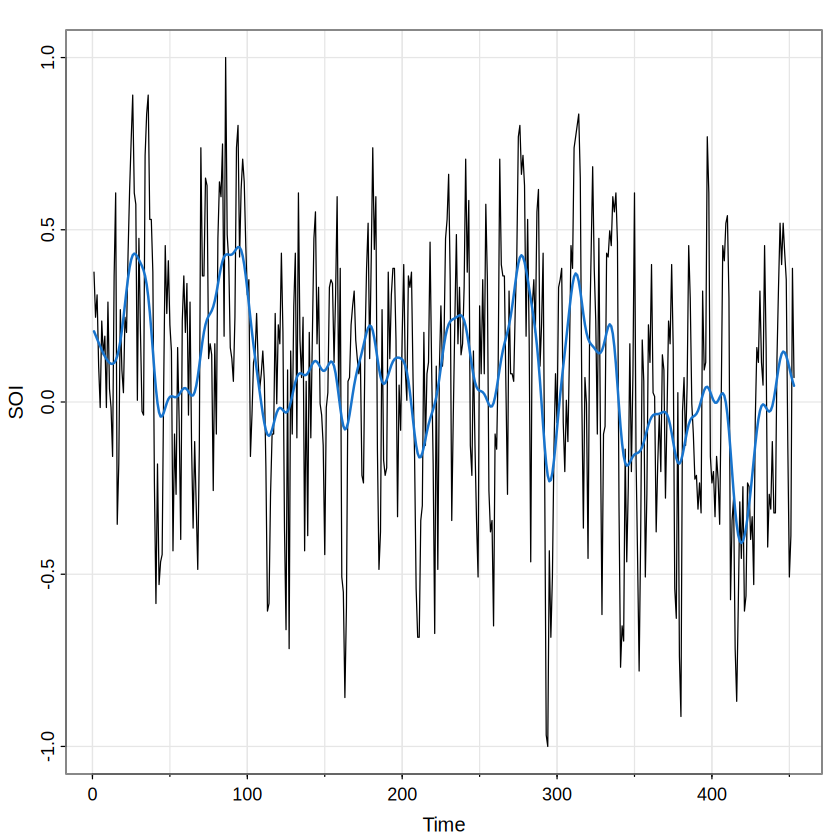

In [27]:
tsplot(soi, col=rgb(.5,.6,.85,.9), ylim=c(-1,1.15))
lines(ksmooth(time(soi), soi, "normal", bandwidth=1), lwd=2, col=4)
par(fig=c(.65,1,.75,1), new=TRUE)
curve(dnorm(x), -3,3, xaxt="n", yaxt="n", ann=FALSE, col=4)
par(fig=c(0,1,0,1), new=FALSE)

SOI = ts(soi, freq=1)
tsplot(SOI)
lines(ksmooth(time(SOI), SOI, "normal", bandwidth=12), lwd=2, col=4)

**Graph interpretation.** The first time axis measures calendar **years** (monthly values at intervals of $1/12$). The second is an observation-count time axis after converting `freq=1`; using `bandwidth=12` approximates the same one-year smoothing span as `bandwidth=1` on the original year scale. Smoothness depends on both bandwidth and the time units. The smooth curve is an exploratory estimate, not a confidence interval or fitted stochastic forecast.

## 13. Lowess and loess smoothing

**Lowess** (locally weighted scatterplot smoothing) fits weighted local regressions. The fraction $f$ determines the portion of nearby observations used. A small fraction follows short-term movements; a large fraction emphasizes long-run patterns. **Loess** is a related local regression procedure and can also return approximate standard errors used for pointwise uncertainty bands.

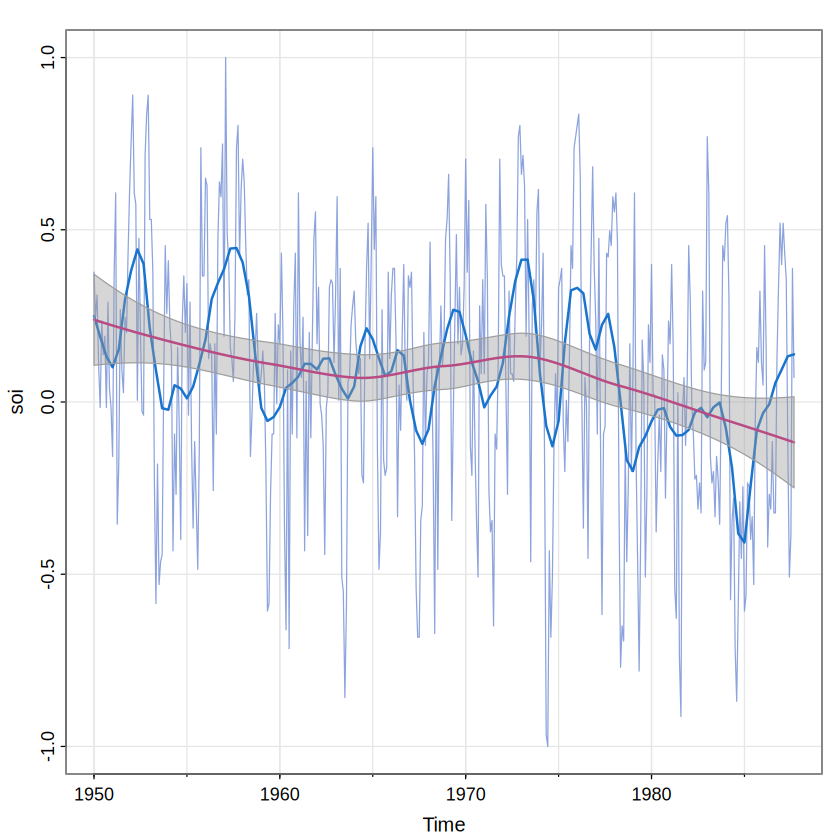

In [28]:
tsplot(soi, col=rgb(.5,.6,.85,.9))
lines(lowess(soi, f=.05), lwd=2, col=4)
# lines(lowess(soi), lty=2, lwd=2, col=2)
lo = predict(loess(soi ~ time(soi)), se=TRUE)
trnd = ts(lo$fit, start=start(soi), frequency=frequency(soi))
lines(trnd, col=6, lwd=2)
L = trnd - qt(.975, lo$df)*lo$se
U = trnd + qt(.975, lo$df)*lo$se
xx = c(time(soi), rev(time(soi)))
yy = c(as.numeric(L), rev(as.numeric(U)))
polygon(xx, yy, border=8, col=gray(.6, alpha=.4))

**Graph interpretation.** The narrow-span lowess curve follows fluctuations more closely and may reveal slow El Niño-related cycles after shorter variations are suppressed. The wider-span loess curve represents a smoother background trajectory. The shaded band uses the reported local fit standard errors and $t$ quantiles: it is an **approximate pointwise band**, not a simultaneous confidence envelope, a prediction interval, or a complete account of serial dependence. Apparent long-run slopes should not be interpreted causally from this graph.

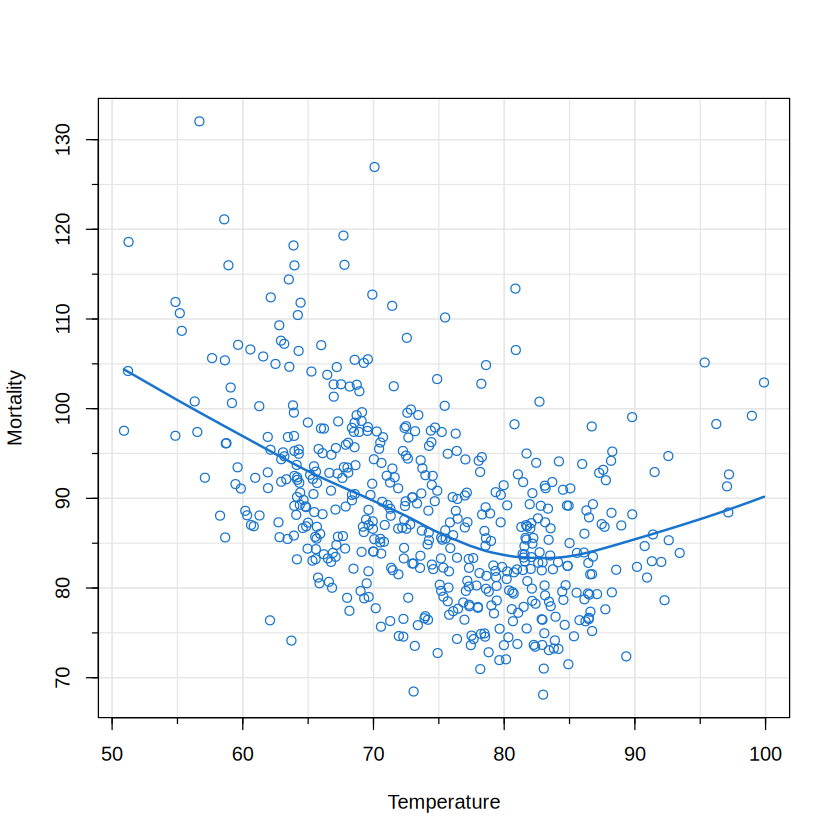

In [29]:
plot(tempr, cmort, xlab="Temperature", ylab="Mortality",
     col="dodgerblue3", panel.first=Grid())
lines(lowess(tempr,cmort), col=4, lwd=2)

**Graph interpretation.** Here the horizontal axis is **temperature in °F**, not time; the vertical axis is mortality. The local smooth has a U-shaped pattern, with the chapter describing a minimum near **83 °F**. Mortality is higher in both colder and hotter portions of the observed temperature range. This is an observational association; the smooth does not adjust for seasonality, pollution, or other potentially relevant variables.

## 14. Additive time-series decomposition

**Trend** $T_t$ describes slow change, **seasonal component** $S_t$ repeats approximately at the same phase of each seasonal cycle, and **remainder/noise** $N_t$ contains variations not captured by those components.

$$
x_t=T_t+S_t+N_t.
$$

**STL** (*seasonal and trend decomposition using loess*) estimates the components by smoothing. For quarterly observations, the seasonal period is four observations. `s.window="periodic"` forces the seasonal shape to repeat, while a numeric seasonal span lets it change gradually. Components depend on the chosen smoothing settings; they are not uniquely identified by the data alone.

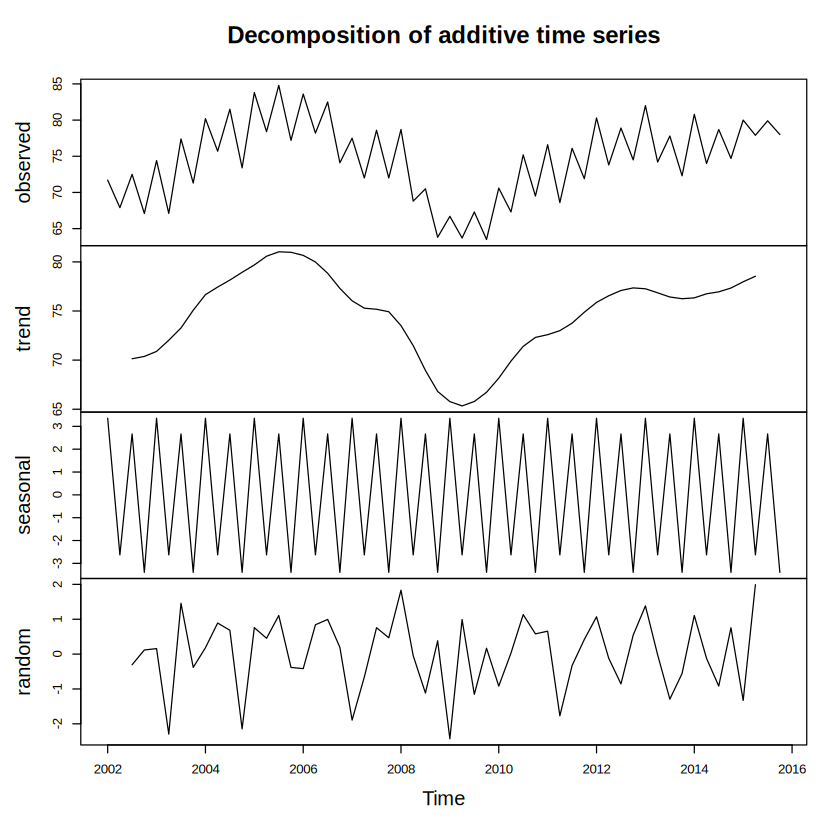

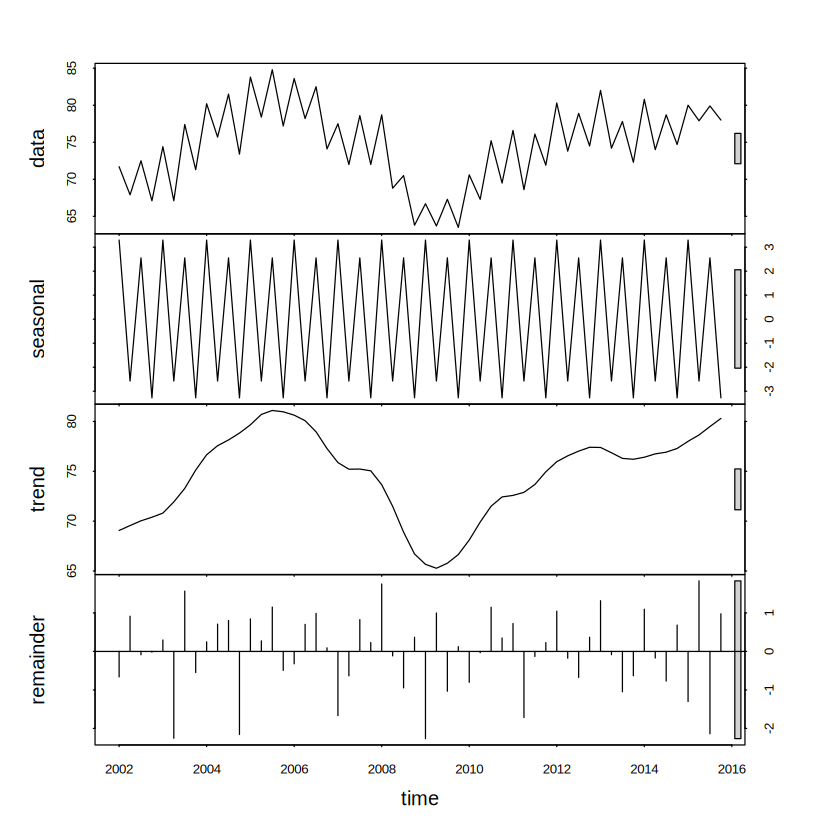

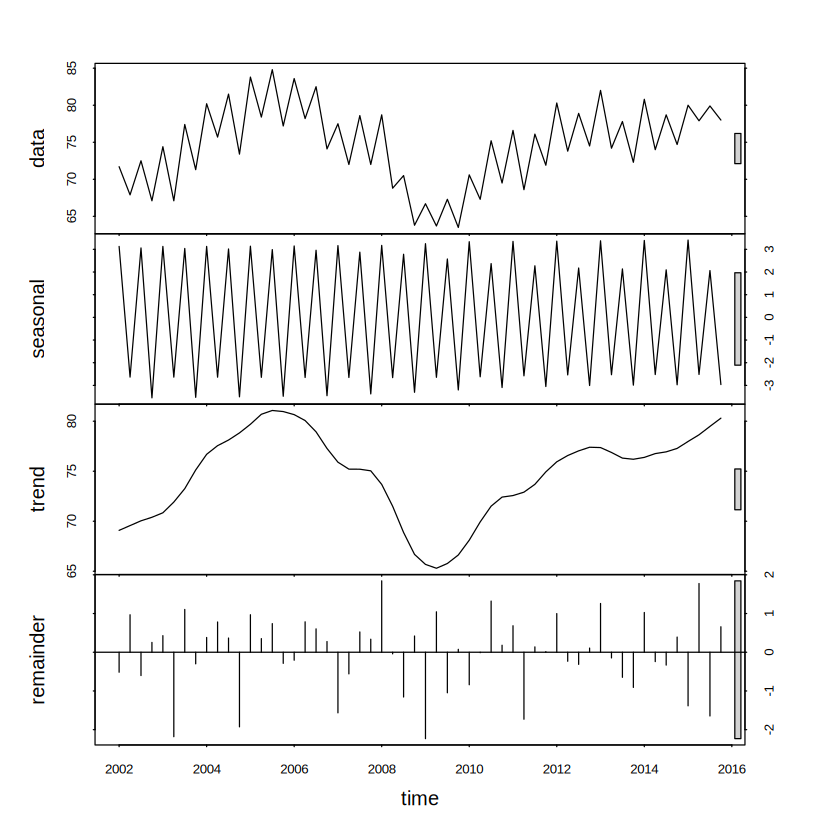

In [30]:
x = window(hor, start=2002)
plot(decompose(x))
plot(stl(x, s.window="periodic"))
plot(stl(x, s.window=15))

Max reconstruction error: 1.4211e-14 
 seasonal     trend remainder 
    0.000    74.639    -0.004 


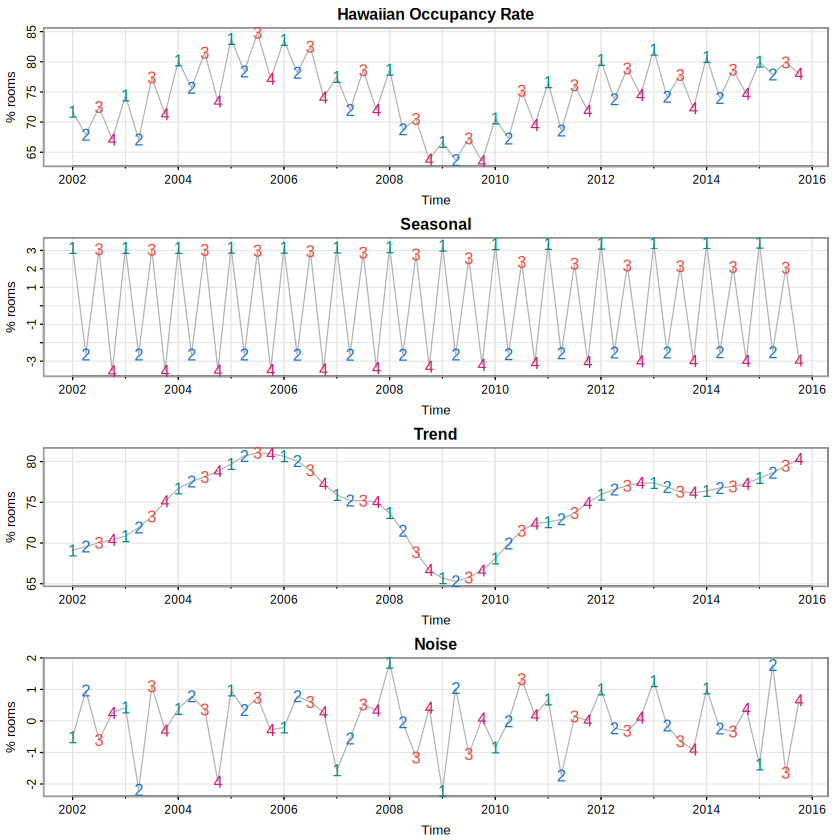

In [31]:
culer = c("cyan4",4,2,6)
par(mfrow=c(4,1), cex.main=1)
x = window(hor, start=2002)
out = stl(x, s.window=15)$time.series
tsplot(x, main="Hawaiian Occupancy Rate", ylab="% rooms", col=gray(.7))
text(x, labels=rep(1:4,length.out=length(x)), col=culer, cex=1.25)
tsplot(out[,1], main="Seasonal", ylab="% rooms", col=gray(.7))
text(out[,1], labels=rep(1:4,length.out=nrow(out)), col=culer, cex=1.25)
tsplot(out[,2], main="Trend", ylab="% rooms", col=gray(.7))
text(out[,2], labels=rep(1:4,length.out=nrow(out)), col=culer, cex=1.25)
tsplot(out[,3], main="Noise", ylab="% rooms", col=gray(.7))
text(out[,3], labels=rep(1:4,length.out=nrow(out)), col=culer, cex=1.25)
par(mfrow=c(1,1))

cat("Max reconstruction error:",
    max(abs(as.numeric(x)-rowSums(out)), na.rm=TRUE), "\n")
print(round(colMeans(out, na.rm=TRUE), 3))

**Graph interpretation.** The observed Hawaiian hotel occupancy rate appears in percent of rooms; all components are in **percentage points**. The seasonal panel shows systematically higher occupancy contributions in quarters 1 and 3 and lower contributions in quarters 2 and 4 (the book describes deviations of roughly 2–4 percentage points). The trend panel captures gradual occupancy changes rather than quarterly alternation; the remainder displays the unexplained short-term deviations. The maximum reconstruction discrepancy is **$1.42\times10^{-14}$**, effectively zero at floating-point precision, confirming that the three extracted components sum to the observed values. Remaining structure in the noise component would suggest decomposition has not removed all temporal dependence. This decomposition is descriptive rather than a validated occupancy forecast.

**Reference**

Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press.